In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment
from sklearn.datasets import make_moons


In [2]:
D = 2
N = 2_000
SEED = 42

phase1_steps = 500
phase2_steps = 500
batch_size = 256
lr = 1e-3
eps_max = 0.05
cd_weight = 1.0

np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
def sample_data(batch_size):
    if D == 1:
        return sample_data_1d(batch_size)

    return sample_moon(batch_size)

def sample_moon(batch_size):
    X, y = make_moons(batch_size, noise=0.1)
    return torch.from_numpy(X).float()

def sample_blobs(batch_size, n_modes=8, radius=2.0, std=0.1):
    angles = torch.randint(0, n_modes, (batch_size,)).float() * (2 * 3.14159265 / n_modes)
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1) + 0.5
    return centers + std * torch.randn(batch_size, 2)

def sample_data_1d(batch_size: int) -> np.ndarray:
    mixture_prob = np.array([0.55, 0.45], dtype=float)
    mixture_mus = np.array([-0.85, 1.5], dtype=float)
    mixture_sigmas = np.array([0.65, 0.25], dtype=float)
    
    rand_idx = np.random.choice(range(len(mixture_prob)), size=batch_size, p=mixture_prob)
    means = mixture_mus[rand_idx]
    stds = mixture_sigmas[rand_idx]

    return torch.from_numpy(np.random.normal(loc=means, scale=stds)).to(torch.float32).unsqueeze(-1)
 
def sample_noise(batch_size):
    return sample_blobs(batch_size)
    # return torch.randn(batch_size, D)

In [4]:
class PotentialModel(nn.Module):

    def __init__(self, dim = 2, hidden_dim = 256):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)

def grad_V(V, x):
    x = x.detach().requires_grad_(True)
    energy = V(x).sum()
    (g,) = torch.autograd.grad(energy, x, create_graph=True)
    return g

In [5]:
def ot_couple(x0, x1):
    cost = torch.cdist(x0, x1) ** 2
    row_ind, col_ind = linear_sum_assignment(cost.detach().numpy())

    return x0[row_ind], x1[col_ind]


def phase1_loss(V, batch_size):
    x0 = sample_noise(batch_size)
    x1 = sample_data(batch_size)

    if D > 1:
        x0, x1 = ot_couple(x0, x1)

    t = torch.rand(batch_size, 1)
    x_t = (1 - t) * x0 + t * x1
    # TODO: Why is it x0 - x1 here and not the other way around??
    target = x0 - x1

    pred = grad_V(V, x_t)
    return ((pred - target) ** 2).sum(dim=1).mean()

In [6]:
def langevin_negative_samples(V, x_int, n_steps = 20, step_size = 0.01, eps_max = 0.05):
    x = x_int.clone().detach()
    for _ in range(n_steps):
        g = grad_V(V, x).detach()
        noise = torch.randn_like(x)

        x = x - step_size * g + (2 * step_size * eps_max) ** 0.5 * noise
        x = x.detach()

    return x

def ode_integrate(V, x, n_steps = 50, dt = None):
    dt = dt if dt is not None else 1.0 / n_steps
    x = x.clone().detach()
    for _ in range(n_steps):
        g = grad_V(V, x).detach()
        x = x - dt * g

    return x

def phase2_loss(V, batch_size, eps_max = 0.05, cd_weight = 1.0):
    ot_loss = phase1_loss(V, batch_size)

    x_data = sample_data(batch_size)

    half = batch_size // 2
    x0 = sample_noise(batch_size - half)
    x0_pushed = ode_integrate(V, x0, n_steps=10)
    x_init = torch.cat([x_data[:half] + 0.1 * torch.randn(half, D), x0_pushed], dim=0)

    x_neg = langevin_negative_samples(V, x_init, eps_max=eps_max)

    cd_loss = V(x_data).mean() / eps_max - V(x_neg).mean() / eps_max
    return ot_loss + cd_weight * cd_loss

In [23]:

x_0 = sample_noise(batch_size)
x_0[:128].shape

torch.Size([128, 2])

In [7]:
@torch.no_grad()
def sample(V, n_samples, ode_steps = 50, langevin_steps = 10, eps_max = 0.05):
    x = sample_noise(n_samples)
    with torch.enable_grad():
        x = ode_integrate(V, x, n_steps=ode_steps)
        x = langevin_negative_samples(V, x, n_steps=langevin_steps, eps_max=eps_max)

    return x

In [ ]:
V = PotentialModel(dim=D)
opt = torch.optim.Adam(V.parameters(), lr=lr)

V.train()

phase1_losses = []
phase2_losses = []

with tqdm(range(phase1_steps)) as pb:
    for i in pb:
        opt.zero_grad()
        loss = phase1_loss(V, batch_size)
        loss.backward()
        opt.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}'})
        phase1_losses.append(loss.item())

with tqdm(range(phase2_steps)) as pb:
    for i in pb:
        opt.zero_grad()
        loss = phase2_loss(V, batch_size, eps_max, cd_weight)
        loss.backward()
        opt.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}'})
        phase2_losses.append(loss.item())


100%|██████████| 500/500 [00:28<00:00, 17.32it/s, Loss=1.34] 


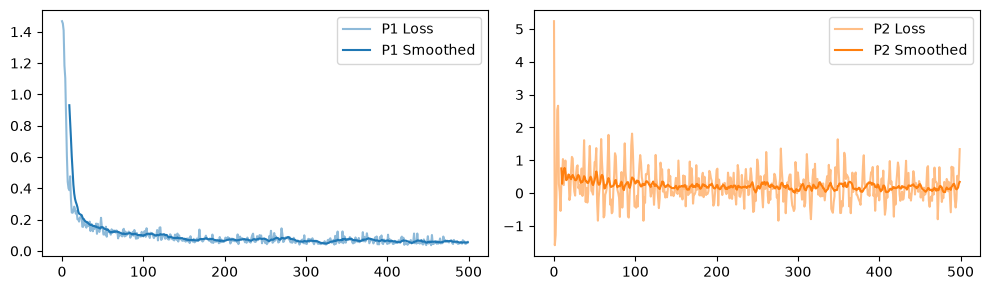

In [9]:
def plot_loss(ax, loss, color, title):
    ax.plot(loss, label=f'{title} Loss', color=color, alpha=0.5)
    ws = 10
    smoothed = np.convolve(loss, np.ones(ws) / ws, mode="valid")
    ax.plot(np.arange(ws-1, len(loss)), smoothed, label=f"{title} Smoothed", color=color)
    ax.legend()

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

plot_loss(axs[0], phase1_losses, 'tab:blue', 'P1')
plot_loss(axs[1], phase2_losses, 'tab:orange', 'P2')


fig.tight_layout()

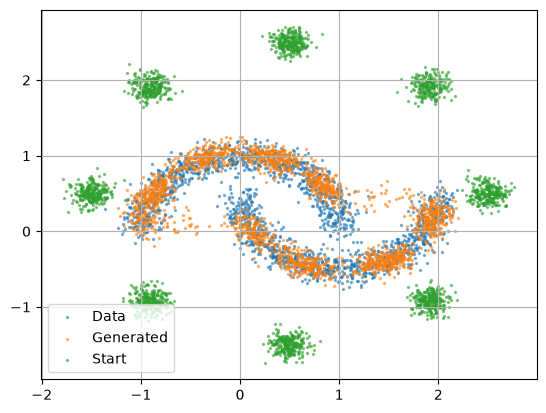

In [10]:

V.eval()

data = sample_data(N)
samples = sample(V, n_samples=N)
blobs = sample_blobs(N)

fig, ax = plt.subplots()

if D > 1:
    ax.scatter(data[:, 0], data[:, 1], alpha=0.5, s=2, label="Data")
    ax.scatter(samples[:, 0], samples[:, 1], alpha=0.5, s=2, label="Generated")
    ax.scatter(blobs[:, 0], blobs[:, 1], alpha=0.5, s=2, label="Start")
else:
    ax.hist(data, bins=100, alpha=0.5, color="tab:blue", label="Data")
    ax.hist(samples, bins=100, alpha=0.5, color="tab:orange", label="Generated")

plt.legend()
plt.grid()
plt.show()

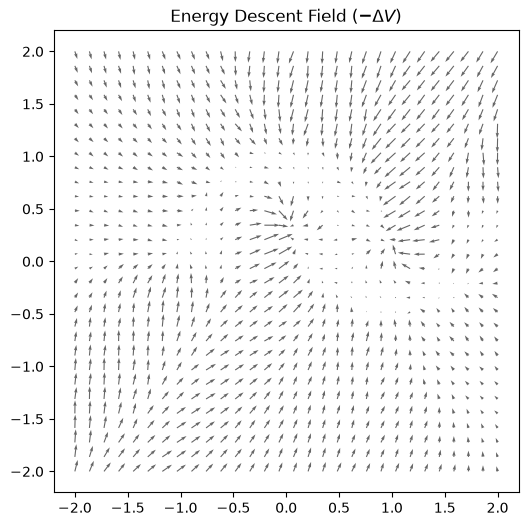

In [11]:
def plot_energy_gradient_field(ax, V, x_range=(-2, 2), y_range=(-2, 2), n_grid=30):
    xs = np.linspace(*x_range, n_grid)
    ys = np.linspace(*y_range, n_grid)
    xx, yy = np.meshgrid(xs, ys)

    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32)

    g = grad_V(V, grid).detach().numpy()

    u = -g[:, 0].reshape(n_grid, n_grid)
    v = -g[:, 1].reshape(n_grid, n_grid)

    ax.quiver(xx, yy, u, v, color="black", alpha=0.6)
    ax.set_title(r"Energy Descent Field ($-\Delta V$)")


fig, ax = plt.subplots(figsize=(6,6))
plot_energy_gradient_field(ax, V)

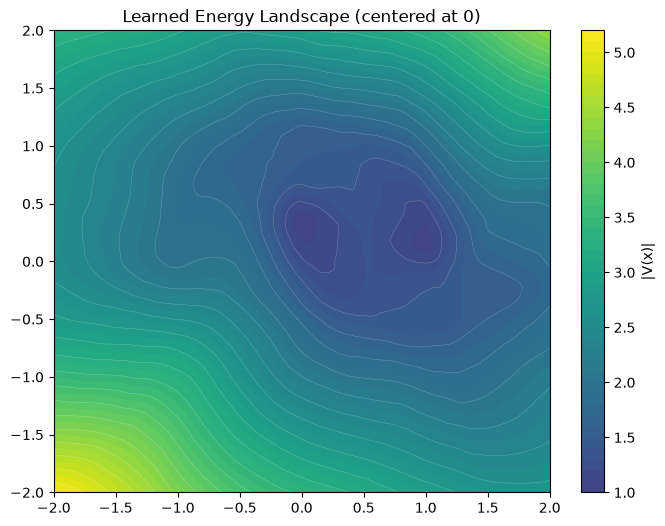

In [12]:
@torch.no_grad()
def plot_energy_landscape(ax, V, x_range=(-2, 2), y_range=(-2, 2), n_grid=200):
    xs = np.linspace(*x_range, n_grid)
    ys = np.linspace(*y_range, n_grid)
    xx, yy = np.meshgrid(xs, ys)

    grid = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32)
    energy = V(grid).squeeze(-1).reshape(n_grid, n_grid).numpy()

    energy_abs = np.abs(energy)
    cf = ax.contourf(xx, yy, energy_abs, levels=50, cmap="viridis", vmin=0)
    plt.colorbar(cf, ax=ax, label="|V(x)|")
    ax.contour(xx, yy, energy, levels=20, colors="white", linewidths=0.3, alpha=0.3)

    ax.set_title("Learned Energy Landscape (centered at 0)")


fig, ax = plt.subplots(figsize=(8, 6))
plot_energy_landscape(ax, V)
plt.show()